# Task 3 — Car Price Prediction
**CodeAlpha · Data Science Internship**

**Goal:** train a **regression** model that predicts a car's price based on its features (brand, horsepower, mileage, age, etc.).

This notebook works with the two most common files for this task:
- *CarPrice_Assignment.csv* (target column `price`)
- *car data.csv* from CarDekho (target column `Selling_Price`)

Place the CSV next to the notebook and adjust `DATA_PATH`.

## 1st Step : Import librairies

In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "car data.csv"

## Step 2 — Load and Check Out the Data

In [4]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip() 
print("Dimensions :", df.shape)
print("\n Missing values :", int(df.isnull().sum().sum()))
print("\n Duplicated values :", int(df.duplicated().sum()))
df.info()

Dimensions : (301, 9)

 Missing values : 0

 Duplicated values : 2
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


## Step 3 — Cleaning and creating variables (*feature engineering*)
Depending on the file, we prepare differently:
- **CarPrice_Assignment**: we remove the `car_ID` identifier (useless for predicting), and we extract the **brand** from `CarName` (with correction of some known typos).
- **car data (CarDekho)**: we replace the `Year` with the vehicle's **age** (more meaningful for a model), and we remove the exact `Car_Name`.

In both cases, we remove any potential duplicates.

In [5]:
# 1. Suppression des doublons
df = df.drop_duplicates().copy()

# 2. Identification du dataset et préparation
if "Selling_Price" in df.columns:
    # Dataset CarDekho
    TARGET = "Selling_Price"

    # Calcul de l'âge du véhicule
    ref_year = df["Year"].max() + 1
    df["Car_Age"] = ref_year - df["Year"]

    # Suppression de Year et Car_Name
    df = df.drop(columns=["Year", "Car_Name"], errors="ignore")

elif "price" in df.columns:
    # Dataset CarPrice_Assignment
    TARGET = "price"

    # Suppression de l'identifiant
    df = df.drop(columns=["car_ID"], errors="ignore")

    # Extraction de la marque depuis CarName
    if "CarName" in df.columns:
        brand = df["CarName"].str.split().str[0].str.lower()

        # Correction des fautes de frappe
        brand = brand.replace({
            "maxda": "mazda",
            "porcshce": "porsche",
            "toyouta": "toyota",
            "vokswagen": "volkswagen",
            "vw": "volkswagen"
        })

        df["brand"] = brand

        # Suppression du nom exact du véhicule
        df = df.drop(columns=["CarName"])

else:
    raise ValueError(
        "Colonne cible introuvable : attendu 'price' ou 'Selling_Price'"
    )

# 3. Identification des variables explicatives
X = df.drop(columns=[TARGET])
y = df[TARGET]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# 4. Affichage des résultats
print("Variable cible :", TARGET)
print("Dimensions du dataset :", df.shape)
print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

Variable cible : Selling_Price
Dimensions du dataset : (299, 8)
Variables numériques : ['Present_Price', 'Driven_kms', 'Owner', 'Car_Age']
Variables catégorielles : ['Fuel_Type', 'Selling_type', 'Transmission']


## Step 4 — Visual Exploration
1. How is the price distributed?
2. Which numerical variables are most related to the price?
3. Does the price vary depending on the categories (fuel, gearbox, etc.)?

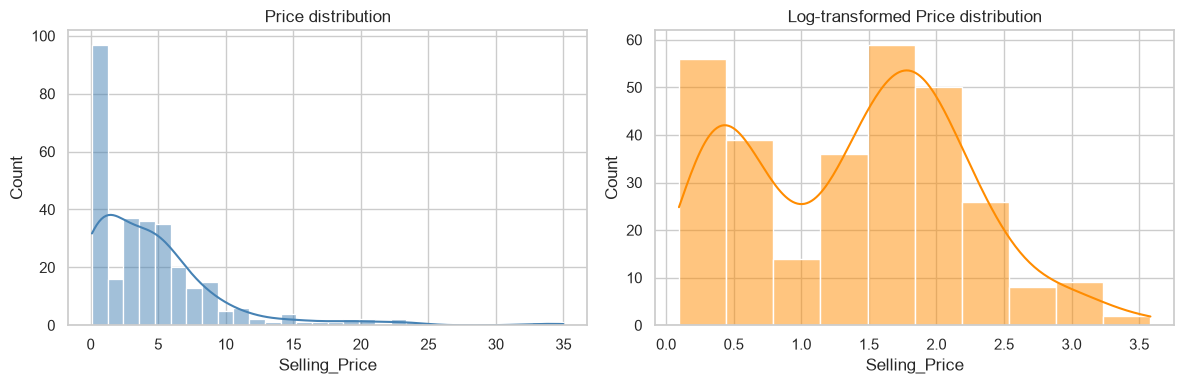

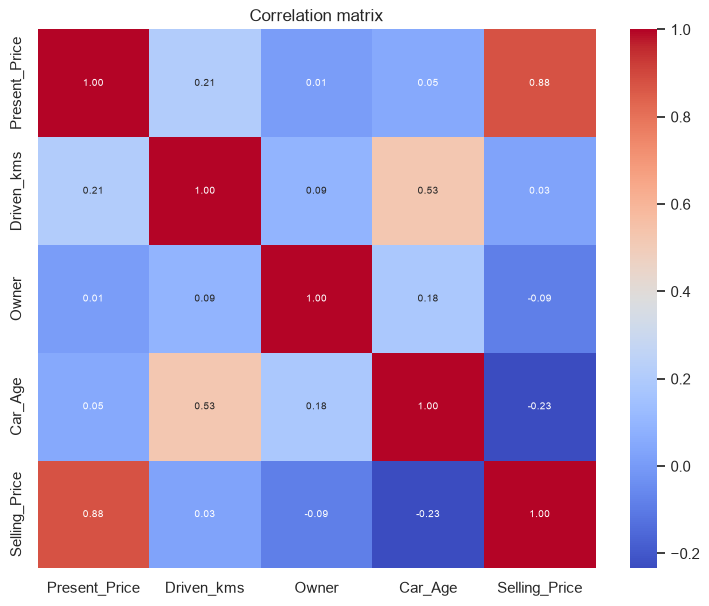

Variables most correlated with price:
Present_Price    0.88
Car_Age          0.23
Owner            0.09
Driven_kms       0.03
Name: Selling_Price, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Price distribution")
sns.histplot(np.log1p(df[TARGET]), kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Log-transformed Price distribution")
plt.tight_layout()
plt.show()

corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.show()

print("Variables most correlated with price:")
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(6).round(2))

- **Distribution des prix :** les prix de vente sont asymétriques à droite, avec une majorité de véhicules à prix faibles et quelques valeurs très élevées. La transformation logarithmique réduit cette asymétrie.

- **Matrice de corrélation :** Present_Price présente une forte corrélation positive avec Selling_Price (0.88). Car_Age présente une faible corrélation négative (-0.23), tandis que Owner (-0.09) et Driven_kms (0.03) ont des corrélations très faibles.

**Conclusion :** Present_Price est la variable la plus liée au prix de vente. La transformation logarithmique peut être envisagée pour améliorer la modélisation.

C:\Users\HP\AppData\Local\Temp\ipykernel_17320\1107411385.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=c, y=TARGET, data=df, ax=ax, palette="Set2", legend=False)
C:\Users\HP\AppData\Local\Temp\ipykernel_17320\1107411385.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=c, y=TARGET, data=df, ax=ax, palette="Set2", legend=False)
C:\Users\HP\AppData\Local\Temp\ipykernel_17320\1107411385.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=c, y=TARGET, data=df, ax=ax, palette="Set2", legend=False)


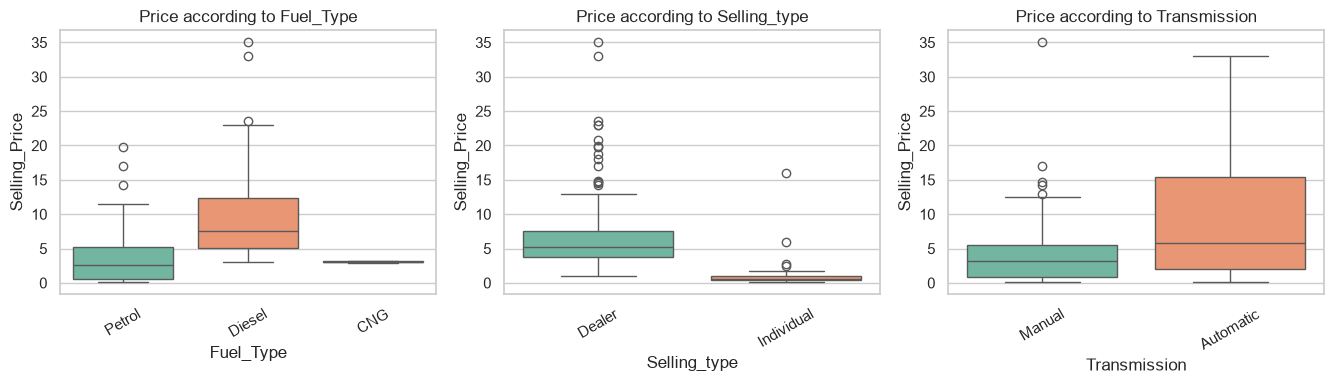

In [8]:
cats_to_plot =[c for c in cat_cols if df[c].nunique() <= 8][:4]
if cats_to_plot:
    fig, axes = plt.subplots(1, len(cats_to_plot), figsize=(4.5 * len(cats_to_plot), 4))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cats_to_plot):
        sns.boxplot(x=c, y=TARGET, data=df, ax=ax, palette="Set2", legend=False)
        ax.set_title(f"Price according to {c}")
        ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()

- **Fuel_Type:** Diesel cars generally have higher selling prices than petrol cars. CNG cars show a very limited price variation.
- **Selling_type:** Dealer sales have significantly higher prices than individual sales.
- **Transmission:** Automatic cars tend to have higher selling prices and greater price variability than manual cars.

**Conclusion:** Fuel type, selling type, and transmission appear to influence selling prices, although some outliers are present in all three distributions.

## Step 5 — Prepare the data
- We separate `X` (features) and `y` (prices).
- 80% for training, 20% for testing.
- A **preprocessor** automatically applies: scaling of numeric variables (`StandardScaler`) and turning categories into 0/1 columns (`OneHotEncoder`). Integrated into a `Pipeline`, it’s learned only on the training set, which avoids any data leakage into the test set.

In [9]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (239, 7) | Test : (60, 7)


## Step 6 — Train and Compare Several Models
Four models of increasing complexity, evaluated with:
- **R²**: proportion of price variability explained (1 = perfect),
- **MAE**: mean absolute error (in the price unit),
- **RMSE**: like MAE but penalizes larger errors more.

5-fold cross-validation on the training set gives a more stable estimate.

In [12]:
models = {
    "Regression Lineaire": LinearRegression(),
    "Ridge" : Ridge(alpha = 1.0),
    "Random Forest" : RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting" : GradientBoostingRegressor(random_state=RANDOM_STATE),
    }

rows, fitted = [], {}
for name, reg in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", reg)
    ])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "model": name,
        "R² CV (moy.)": cv_r2.mean(),
        "R²": r2_score(y_test, pred),
        "MAE Test": mean_absolute_error(y_test, pred),
        "RMSE Test": np.sqrt(mean_squared_error(y_test, pred))
    })
    
results = pd.DataFrame(rows).sort_values(by="R² CV (moy.)", ascending=False).reset_index(drop=True)
results.round(3)

,model,R² CV (moy.),R²,MAE Test,RMSE Test
0,Random Forest,0.873,0.470,1.531,3.695
1,Ridge,0.870,0.753,1.480,2.523
2,Regression Lineaire,0.868,0.753,1.473,2.525
3,Gradient Boosting,0.866,0.730,1.178,2.638


## Step 7 — Evaluate the Best Model
We keep the model with the best R² in cross-validation. Then, We compare actual prices with predicted prices: the closer the points are to the diagonal, the better the model. The residual (error) plot shouldn’t show any obvious pattern.

Best model: Random Forest


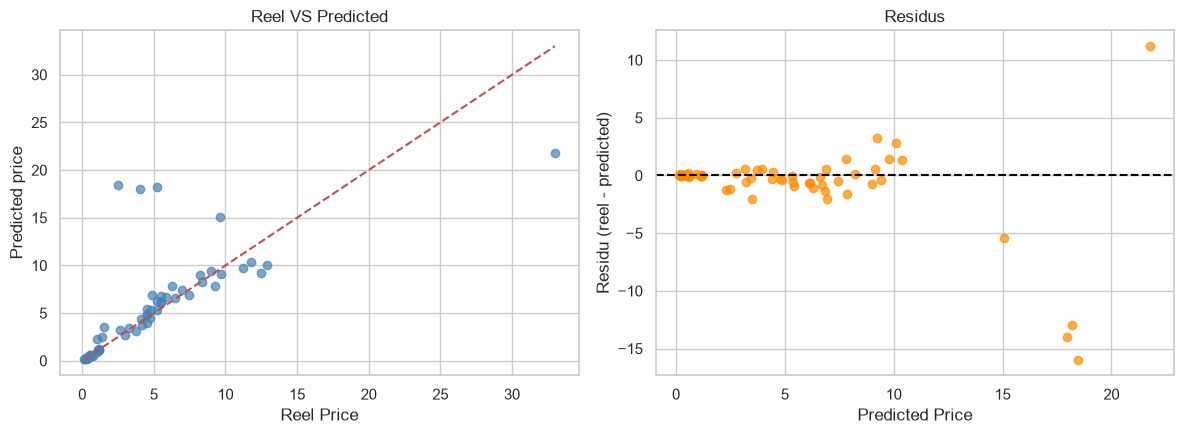

In [14]:
best_name = results.loc[0, "model"]
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.7, color="steelblue")
lims=[min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel("Reel Price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Reel VS Predicted")

axes[1].scatter(pred, y_test-pred, alpha=0.7, color="darkorange")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residu (reel - predicted)")
axes[1].set_title("Residus")
plt.tight_layout()
plt.show()

**Model Performance: Actual vs Predicted & Residuals**
- **Actual vs Predicted:** Most predictions are close to the ideal diagonal line, indicating good model performance. However, some observations show significant prediction errors, especially for higher prices.
- **Residuals:** Most residuals are centered around zero, but several large residuals indicate the presence of important prediction errors and outliers.

**Conclusion:** The model performs reasonably well for lower-priced cars but struggles to predict higher-priced vehicles accurately.

## Step 8 — Which features influence the price the most? 
Tree-based models (Random Forest, Gradient Boosting) provide the importance of each variable.

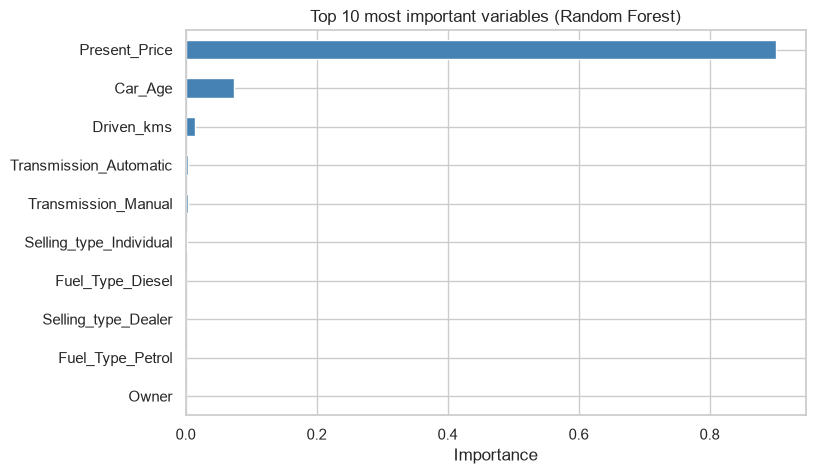

In [20]:
tree_name = best_name
tree_pipe = fitted[tree_name]
names = tree_pipe.named_steps["preprocessor"].get_feature_names_out()
imp = pd.Series(tree_pipe.named_steps["model"].feature_importances_, index=names)
imp.index = [n.split("__", 1)[1] for n in imp.index]
top = imp.sort_values(ascending=False).head(10).iloc[::-1]

plt.figure(figsize=(8, 5))
top.plot(kind="barh", color="steelblue")
plt.title(f"Top 10 most important variables ({tree_name})")
plt.xlabel("Importance")
plt.show()

**Feature Importance (Random Forest)**
- **Present_Price** is by far the most important feature, contributing approximately 90% of the total importance.
- **Car_Age** is the second most important variable, followed by Driven_kms, with a much smaller contribution.
- Other variables, such as transmission, fuel type, selling type, and owner, have very little influence on the model's predictions.

**Conclusion:** The model relies mainly on the vehicle's present price to predict its selling price, while the other features contribute much less.

## Step 9 — Predict the price of a car
We take a car from the test set and compare it with the actual price.

In [21]:
exemple = X_test.iloc[[0]]
print("Features :")
print(exemple.T.to_string())
print(f"\nPredicted price : {best.predict(exemple)[0]:.2f}")
print(f"Actual price   : {y_test.iloc[0]:.2f}")

Features :
                  283
Present_Price    11.8
Driven_kms       9010
Fuel_Type      Petrol
Selling_type   Dealer
Transmission   Manual
Owner               0
Car_Age             3

Predicted price : 9.42
Actual price   : 8.99


The model predicts a selling price of 9.42, while the actual price is 8.99.

The prediction error is only 0.43, representing approximately 4.78% of the actual price.

**Conclusion:** The model provides a relatively accurate prediction for this vehicle, with a small difference between the predicted and actual prices.

## Conclusion
- The best model explains a large part of the price variation (see R² above), with an average error (MAE) given in the unit of price.
- The most important variables are those shown in step 8.
- **Limitations:** modest-sized dataset (a few hundred rows), so scores vary depending on the train/test split; some brands/models are rare.
- **To go further:** tune hyperparameters (`GridSearchCV`), predict `log(price)`, or deploy the model with Streamlit.